# Progetto 5G Networks (Gruppo 2)
## Sorgente da trasmettere:

In [155]:
text = """A Mathematical Theory of Communication
By C. E. SHANNON
INTRODUCTION
   THE recent development of various methods of modulation such as PCM and PPM which exchange bandwidth for signal-to-noise ratio has intensified the interest in a general theory of communication. A basis for such a theory is contained in the important papers of Nyquist and Hartley on this subject. In the present paper we will extend the theory to include a number of new factors, in particular the effect of noise in the channel, and the savings possible due to the statistical structure of the original message and due to the nature of the final destination of the information.   
The fundamental problem of communication is that of reproducing at one point either exactly or approximately a message selected at another point. Frequently the messages have meaning; that is they refer to or are correlated according to some system with certain physical or conceptual entities. These semantic aspects of communication are irrelevant to the engineering problem. The significant aspect is that the actual message is one selected from a set of possible messages. The system must be designed to operate for each possible selection, not just the one which will actually be chosen since this is unknown at the time of design.   
If the number of messages in the set is finite then this number or any monotonic function of this number can be regarded as a measure of the information produced when one message is chosen from the set, all choices being equally likely. As was pointed out by Hartley the most natural choice is the logarithmic function. Although this definition must be generalized considerably when we consider the influence of the statistics of the message and when we have a continuous range of messages, we will in all cases use an essentially logarithmic measure. 

The logarithmic measure is more convenient for various reasons:

1. It is practically more useful. Parameters of engineering importance such as time, bandwidth, number of relays, etc., tend to vary linearly with the logarithm of the number of possibilities. For example, adding one relay to a group doubles the number of possible states of the relays. It adds 1 to the base 2 logarithm of this number. Doubling the time roughly squares the number of possible messages, or doubles the logarithm, etc.
   
2. It is nearer to our intuitive feeling as to the proper measure. This is closely related to (1) since we intuitively measures entities by linear comparison with common standards. One feels, for example, that two punched cards should have twice the capacity of one for information storage, and two identical channels twice the capacity of one for transmitting information.
   
3. It is mathematically more suitable. Many of the limiting operations are simple in terms of the logarithm but would require clumsy restatement in terms of the number of possibilities.
   
The choice of a logarithmic base corresponds to the choice of a unit for measuring information. If the base 2 is used the resulting units may be called binary digits, or more briefly _bits_, a word suggested by J. W. Tukey. A device with two stable positions, such as a relay or a flip-flop circuit, can store one bit of information. $N$ such devices can store $N$ bits, since the total number of possible states is $2^N$ and $\log_2 2^N = N$. If the base 10 is used the units may be called decimal digits. Since

$$\log_2 M = \log_{10} M / \log_{10} 2$$

$$= 3.32 \log_{10} M$$

a decimal digit is about $3\frac{1}{3}$ bits. A digit wheel on a desk computing machine has ten stable positions and therefore has a storage capacity of one decimal digit. In analytical work where integration and differentiation are involved the base $e$ is sometimes useful. The resulting units of information will be called natural units. Change from the base $a$ to base $b$ merely requires multiplication by $\log_b a$.

By a communication system we will mean a system of the type indicated schematically in Fig. 1. It consists of essentially five parts:

1. An _information source_ which produces a message or sequence of messages to be communicated to the receiving terminal. The message may be of various types: (a) A sequence of letters as in a telegraph of teletype system; (b) A single function of time $f(t)$ as in radio or telephony; (c) A function of time and other variables as in black and white television — here the message may be thought of as a function $f(x,y,t)$ of two space coordinates and time, the light intensity at point $(x,y)$ and time $t$ on a pickup tube plate; (d) Two or more functions of time, say $f(t)$, $g(t)$, $h(t)$ — this is the case in “three-dimensional” sound transmission or if the system is intended to service several individual channels in multiplex; (e) Several functions of several variables — in color television the message consists of three functions $f(x,y,t)$, $g(x,y,t)$, $h(x,y,t)$ defined in a three-dimensional continuum — we may also think of these three functions as components of a vector field defined in the region — similarly, several black and white television sources would produce “messages” consisting of a number of functions of three variables; (f) Various combinations also occur, for example in television with an associated audio channel.
   
2. A _transmitter_ which operates on the message in some way to produce a signal suitable for transmission over the channel. In telephony this operation consists merely of changing sound pressure into a proportional electrical current. In telegraphy we have an encoding operation which produces a sequence of dots, dashes and spaces on the channel corresponding to the message. In a multiplex PCM system the different speech functions must be sampled, compressed, quantized and encoded, and finally interleaved properly to construct the signal. Vocoder systems, television and frequency modulation are other examples of complex operations applied to the message to obtain the signal.
   
3. The _channel_ is merely the medium used to transmit the signal from transmitter to receiver. It may be a pair of wires, a coaxial cable, a band of radio frequencies, a beam of light, etc.  
   
4. The _receiver_ ordinarily performs the inverse operation of that done by the transmitter, reconstructing the message from the signal.  
   
5. The _destination_ is the person (or thing) for whom the message is intended.   
   
We wish to consider certain general problems involving communication systems. To do this it is first necessary to represent the various elements involved as mathematical entities, suitably idealized from their physical counterparts. We may roughly classify communication systems into three main categories: discrete, continuous and mixed. By a discrete system we will mean one in which both the message and the signal are a sequence of discrete symbols. A typical case is telegraphy where the message is a sequence of letters and the signal a sequence of dots, dashes and spaces. A continuous system is one in which the message and signal are both treated as continuous functions, e.g., radio or television. A mixed system is one in which both discrete and continuous variables appear, e.g., PCM transmission of speech.
We first consider the discrete case. This case has applications not only in communication theory, but also in the theory of computing machines, the design of telephone exchanges and other fields. In addition the discrete case forms a foundation for the continuous and mixed cases which will be treated in the second half of the paper.
"""
print(text)
print(len(text))

A Mathematical Theory of Communication
By C. E. SHANNON
INTRODUCTION
   THE recent development of various methods of modulation such as PCM and PPM which exchange bandwidth for signal-to-noise ratio has intensified the interest in a general theory of communication. A basis for such a theory is contained in the important papers of Nyquist and Hartley on this subject. In the present paper we will extend the theory to include a number of new factors, in particular the effect of noise in the channel, and the savings possible due to the statistical structure of the original message and due to the nature of the final destination of the information.   
The fundamental problem of communication is that of reproducing at one point either exactly or approximately a message selected at another point. Frequently the messages have meaning; that is they refer to or are correlated according to some system with certain physical or conceptual entities. These semantic aspects of communication are irrelev

## Codifica di sorgente

#### Algoritmi per la compressione LZ78

In [156]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [157]:
def lz78_compress_chars(text):
    dizionario = {"": 0}
    out = []
    w = ""
    for c in text:
        if w + c in dizionario:
            w += c
        else:
            out.append((dizionario[w], c))
            dizionario[w + c] = len(dizionario)
            w = ""
    if w:
        out.append((dizionario[w], None))
    return out


def lz78_decompress_chars(coppie):
    frasi = [""]
    out = []
    for idx, c in coppie:
        if c is None:
            out.append(frasi[idx])
        else:
            frase = frasi[idx] + c
            out.append(frase)
            frasi.append(frase)
    return "".join(out)

def _bit_char(alfabeto):
    # +1 per il valore riservato alla coppia finale senza simbolo (None)
    return max(1, math.ceil(math.log2(len(alfabeto) + 1)))


def lz78_to_bits(coppie, alfabeto):
    pos = {c: i for i, c in enumerate(alfabeto)}
    bc = _bit_char(alfabeto)
    out = []
    for k, (idx, c) in enumerate(coppie, start=1):
        n_idx = max(1, math.ceil(math.log2(k)))
        out.append(format(idx, f'0{n_idx}b'))
        val = pos[c] if c is not None else len(alfabeto)
        out.append(format(val, f'0{bc}b'))
    return np.array(list(''.join(out)), dtype=np.uint8)

# Versione che non restituisce errori in caso di mancata ricezione
def bits_to_lz78(bits, alfabeto):
    bc = _bit_char(alfabeto)
    s = ''.join(str(int(b)) for b in bits)
    coppie = []
    i, k = 0, 1
    while i < len(s):
        n_idx = max(1, math.ceil(math.log2(k)))
        if i + n_idx + bc > len(s):
            break                                  # flusso troncato
        idx = int(s[i:i + n_idx], 2)
        val = int(s[i + n_idx:i + n_idx + bc], 2)
        if idx >= k or val > len(alfabeto):
            break                                  # corruzione rilevata
        c = None if val == len(alfabeto) else alfabeto[val]
        coppie.append((idx, c))
        i += n_idx + bc
        k += 1
    return coppie

#### Compressione della sorgente

In [158]:
compresso = lz78_compress_chars(text)
# print(compresso)
print(len(compresso), "coppie")

2162 coppie


In [159]:
alfabeto = sorted(set(text))
bits = lz78_to_bits(compresso, alfabeto)
print(len(bits), "bits")

36984 bits


## Modulazione

In [163]:
# Parametri
SNR_dB = 41
sorgente = bits
N_bit = len(sorgente)

# Mappatura antipodale
simboli = 2 * sorgente.astype(int) - 1; 

# Rumore AWGN
SNR = 10 ** (SNR_dB / 10)          # conversione da dB a scala lineare
sigma = np.sqrt(1 / (2 * SNR))     # deviazione standard
# rumore = sigma * np.random.randn(N_bit)
rng = np.random.default_rng(1) # seed fisso per riproducibilità
rumore = sigma * rng.standard_normal(N_bit)

# Fading: energia di simbolo aleatoria esponenziale (media 1)
# E = np.random.exponential(scale=1.0, size=N_bit)
E = rng.exponential(scale=1.0, size=N_bit) # seed fissato
a = np.sqrt(E)

# Segnale ricevuto
ricevuti = a * simboli + rumore

bit_ricevuti = (ricevuti > 0).astype(int)

print(bit_ricevuti)
print(len(bit_ricevuti))

[0 0 0 ... 0 0 0]
36984


## Decompressione

In [164]:
coppie_ricevute = bits_to_lz78(bit_ricevuti, alfabeto) # bit ricevuti dalla trasmissione
decompresso = lz78_decompress_chars(coppie_ricevute)
# print(decompresso)
print(len(coppie_ricevute), "coppie")

2162 coppie


In [165]:
print(decompresso)

A Mathematical Theory of Communication
By C. E. SHANNON
INTRODUCTION
   THE recent development of various methods of modulation such as PCM and PPM which exchange bandwidth for signal-to-noise ratio has intensified the interest in a general theory of communication. A basis for such a theory is contained in the important papers of Nyquist and Hartley on this subject. In the present paper we will extend the theory to include a number of new factors, in particular the effect of noise in the channel, and the savings possible due to the statistical structure of the original message and due to the nature of the final destination of the information.   
The fundamental problem of communication is that of reproducing at one point either exactly or approximately a message selected at another point. Frequently the messages have meaning; that is they refer to or are correlated according to some system with certain physical or conceptual entities. These semantic aspects of communication are irrelev

In [166]:
print(text == decompresso)

False


In [167]:
errori = [(i, a, b) for i, (a, b) in enumerate(zip(text, decompresso)) if a != b]
print(len(errori), "caratteri diversi")
for i, orig, ric in errori:
    print(f"pos {i}: atteso {orig!r}, ricevuto {ric!r}")

5389 caratteri diversi
pos 1776: atteso 'e', ricevuto ' '
pos 1777: atteso 's', ricevuto 'a'
pos 1778: atteso 's', ricevuto ' '
pos 1779: atteso 'a', ricevuto 's'
pos 1780: atteso 'g', ricevuto 's'
pos 1781: atteso 'e', ricevuto ','
pos 1782: atteso 's', ricevuto ' '
pos 1783: atteso ',', ricevuto 'w'
pos 1784: atteso ' ', ricevuto 'e'
pos 1785: atteso 'w', ricevuto ' '
pos 1786: atteso 'e', ricevuto 'w'
pos 1787: atteso ' ', ricevuto 'i'
pos 1788: atteso 'w', ricevuto 'l'
pos 1789: atteso 'i', ricevuto 'l'
pos 1790: atteso 'l', ricevuto ' '
pos 1791: atteso 'l', ricevuto 'i'
pos 1792: atteso ' ', ricevuto 'n'
pos 1793: atteso 'i', ricevuto ' '
pos 1794: atteso 'n', ricevuto 'a'
pos 1795: atteso ' ', ricevuto 'l'
pos 1796: atteso 'a', ricevuto 'l'
pos 1797: atteso 'l', ricevuto ' '
pos 1798: atteso 'l', ricevuto 'c'
pos 1799: atteso ' ', ricevuto 'a'
pos 1800: atteso 'c', ricevuto 's'
pos 1801: atteso 'a', ricevuto 'e'
pos 1803: atteso 'e', ricevuto ' '
pos 1804: atteso 's', ricevuto '

In [168]:
# --- STATISTICHE DI PRESTAZIONE ---

# 1. Bit Error Rate (BER)
errori_bit = np.sum(bits != bit_ricevuti)
ber = errori_bit / len(bits)

# 2. Character Error Rate (CER)
len_min = min(len(text), len(decompresso))
caratteri_diversi = sum(1 for x, y in zip(text[:len_min], decompresso[:len_min]) if x != y)
mancanti = abs(len(text) - len(decompresso))
errori_char = caratteri_diversi + mancanti
cer = errori_char / len(text)

# 3. Prestazioni di Compressione LZ78
bit_originali = len(text) * 8
bit_compressi = len(bits)
rapporto_compressione = bit_originali / bit_compressi
spazio_risparmiato = (1 - (bit_compressi / bit_originali)) * 100

# Stampa dei risultati
print("=== STATISTICHE DI SIMULAZIONE ===")
print(f"Bit Error Rate (BER):         {ber:.4e} ({errori_bit} bit errati su {len(bits)})")
print(f"Character Error Rate (CER):   {cer:.2%} ({errori_char} caratteri errati su {len(text)}: "
      f"{caratteri_diversi} diversi + {mancanti} mancanti)")
print(f"Rapporto di Compressione:     {rapporto_compressione:.2f}:1")
print(f"Spazio risparmiato:           {spazio_risparmiato:.2f}%")
print(f"Dimensione originale:         {bit_originali} bit")
print(f"Dimensione trasmessa (LZ78):  {bit_compressi} bit")

=== STATISTICHE DI SIMULAZIONE ===
Bit Error Rate (BER):         2.7039e-05 (1 bit errati su 36984)
Character Error Rate (CER):   71.38% (5397 caratteri errati su 7561: 5389 diversi + 8 mancanti)
Rapporto di Compressione:     1.64:1
Spazio risparmiato:           38.86%
Dimensione originale:         60488 bit
Dimensione trasmessa (LZ78):  36984 bit


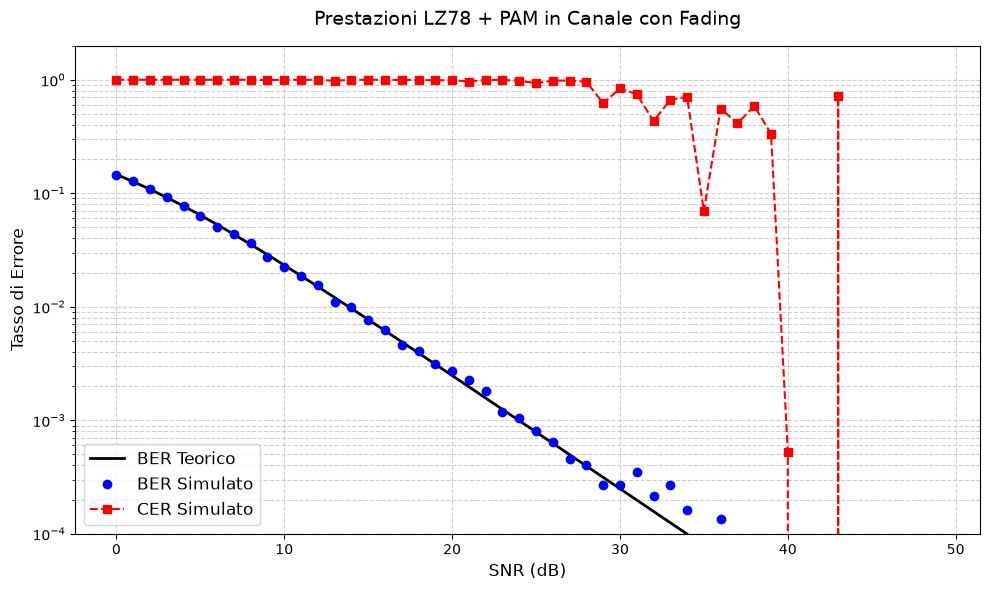

In [169]:
# 1. Definiamo il range di SNR da testare
snr_db_range = np.arange(0, 50, 1)

ber_values = []
cer_values = []

# Mappatura antipodale dei bit compressi
simboli = 2 * bits.astype(int) - 1
N_bit = len(bits)
rng = np.random.default_rng(1)

for snr_db in snr_db_range:
    # Rumore AWGN e Fading
    SNR = 10 ** (snr_db / 10)
    sigma = np.sqrt(1 / (2 * SNR))
    rumore = sigma * rng.standard_normal(N_bit)
    
    E = rng.exponential(scale=1.0, size=N_bit)
    a = np.sqrt(E)
    
    # Trasmissione e Ricezione
    ricevuti = a * simboli + rumore
    bit_ricevuti = (ricevuti > 0).astype(int)
    
    # Calcolo BER (Bit Error Rate)
    errori_bit = np.sum(bits != bit_ricevuti)
    ber = errori_bit / N_bit
    ber_values.append(ber)
    
    # Decompressione LZ78
    coppie_ricevute = bits_to_lz78(bit_ricevuti, alfabeto)
    decompresso = lz78_decompress_chars(coppie_ricevute)
    
    # Calcolo CER (Character Error Rate)
    len_min = min(len(text), len(decompresso))
    errori_char = sum(1 for x, y in zip(text[:len_min], decompresso[:len_min]) if x != y)
    errori_char += abs(len(text) - len(decompresso)) 
    
    cer = errori_char / len(text)
    cer_values.append(cer)

# --- CALCOLO CURVA TEORICA (PAM + Fading) ---
snr_linear_range = 10 ** (snr_db_range / 10)
ber_teorico = 0.5 * (1 - np.sqrt(snr_linear_range / (1 + snr_linear_range)))

# --- CREAZIONE DEL GRAFICO ---
plt.figure(figsize=(10, 6))

# Plot su scala semilogaritmica
plt.semilogy(snr_db_range, ber_teorico, linestyle='-', color='black', linewidth=2, label='BER Teorico')
plt.semilogy(snr_db_range, ber_values, marker='o', linestyle='', color='blue', label='BER Simulato')
plt.semilogy(snr_db_range, cer_values, marker='s', linestyle='--', color='red', label='CER Simulato')

# Formattazione del grafico
plt.title('Prestazioni LZ78 + PAM in Canale con Fading', fontsize=14, pad=15)
plt.xlabel('SNR (dB)', fontsize=12)
plt.ylabel('Tasso di Errore', fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend(fontsize=12)

# Imposta i limiti dell'asse Y per una visualizzazione ottimale
plt.ylim([1e-4, 2]) 

plt.tight_layout()
plt.show()